In [2]:
%pip install matplotlib pillow --quiet
import os
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from  tensorflow import keras
from tensorflow.keras import layers
print("TensorFlow version:", tf.__version__)

Note: you may need to restart the kernel to use updated packages.
TensorFlow version: 2.21.0


In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)
print("pixel min/max :" , x_train.min(), x_train.max())
print("classes:", np.unique(y_train))

x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)
pixel min/max : 0 255
classes: [0 1 2 3 4 5 6 7 8 9]


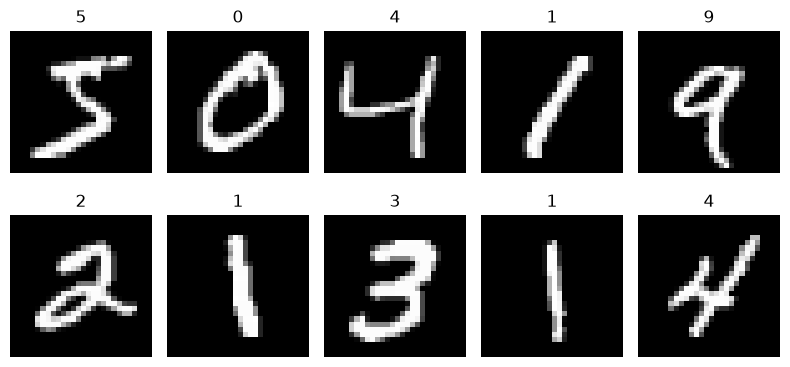

In [4]:
plt.figure(figsize=(8,4))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i], cmap='grey')
    plt.title(y_train[i])
    plt.axis('off')
plt.tight_layout()
plt.show()

In [5]:
import numpy as np
from tensorflow import keras

# Load the data again (fresh, original shape)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize: 0-255  ->  0-1
x_train = x_train / 255.0
x_test = x_test / 255.0

# Reshape for the CNN: (number of images, 28, 28, 1)
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Always check the shapes before training
print("x_train:", x_train.shape)   # must be (60000, 28, 28, 1)
print("x_test:", x_test.shape)     # must be (10000, 28, 28, 1)

x_train: (60000, 28, 28, 1)
x_test: (10000, 28, 28, 1)


In [6]:
np.random.seed(42)
indices = np.random.permutation(len(x_train))
x_train = x_train[indices]
y_train = y_train[indices]
val_size =6000
x_val,y_val = x_train[:val_size],y_train[:val_size]
x_train,y_train = x_train[val_size:],y_train[val_size:]
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("Validation shape:", x_val.shape, y_val.shape)
print("Test shape:", x_test.shape, y_test.shape)


x_train shape: (54000, 28, 28, 1)
y_train shape: (54000,)
Validation shape: (6000, 28, 28, 1) (6000,)
Test shape: (10000, 28, 28, 1) (10000,)


In [7]:
from tensorflow.keras import layers

model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [8]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/5
380/380 ━━━━━━━━━━━━━━━━━━━━ 16s 37ms/step - accuracy: 0.9135 - loss: 0.2860 - val_accuracy: 0.9756 - val_loss: 0.0768
Epoch 2/5
380/380 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.9710 - loss: 0.0920 - val_accuracy: 0.9813 - val_loss: 0.0537
Epoch 3/5
380/380 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - accuracy: 0.9789 - loss: 0.0683 - val_accuracy: 0.9881 - val_loss: 0.0360
Epoch 4/5
380/380 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9819 - loss: 0.0552 - val_accuracy: 0.9876 - val_loss: 0.0336
Epoch 5/5
380/380 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9851 - loss: 0.0466 - val_accuracy: 0.9885 - val_loss: 0.0310


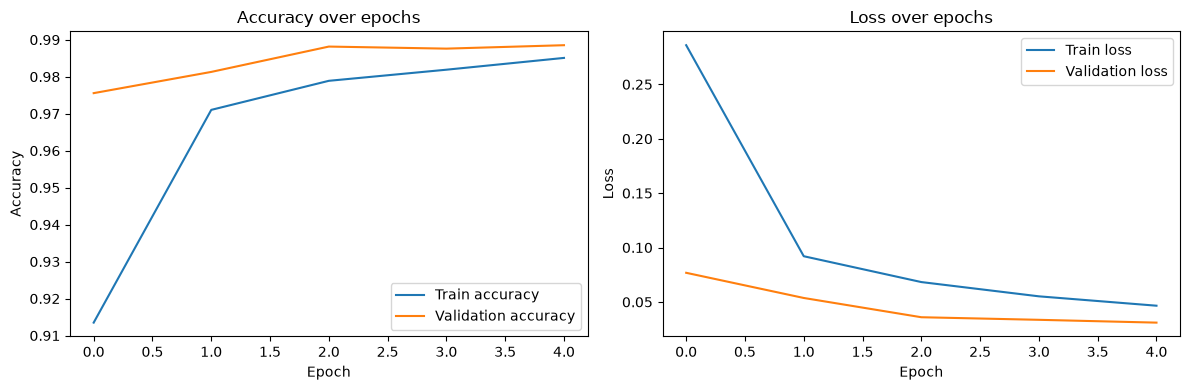

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy over epochs")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss over epochs")
plt.legend()

plt.tight_layout()
plt.show()

In [10]:
test_loss, test_accuracy = model.evaluate(x_test ,y_test)
print("test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9889 - loss: 0.0337
test Accuracy: 0.9889000058174133


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


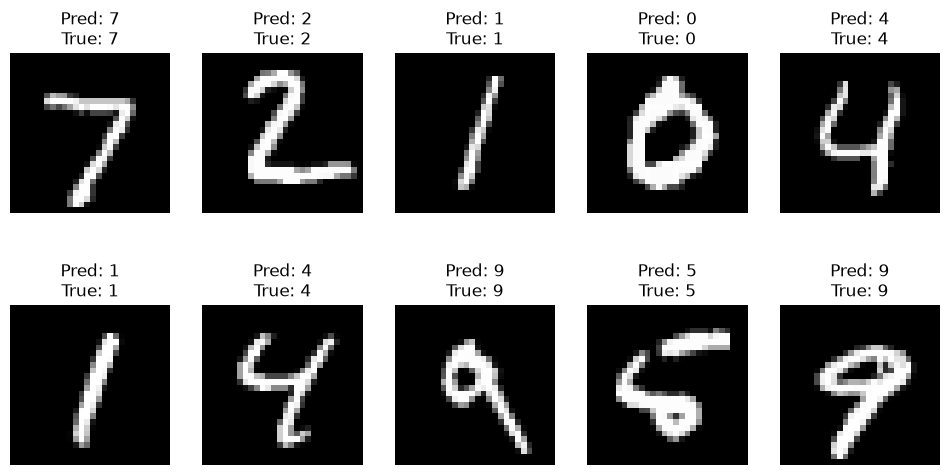

In [11]:
predictions = model.predict(x_test)
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Pred: {np.argmax(predictions[i])}\nTrue: {y_test[i]}")
    plt.axis('off')
plt.show()

In [12]:
model.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.1)
test_loss, test_accuracy = model.evaluate(x_test ,y_test)
print("Final test Accuracy:", test_accuracy)

Epoch 1/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.9865 - loss: 0.0422 - val_accuracy: 0.9919 - val_loss: 0.0276
Epoch 2/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9893 - loss: 0.0355 - val_accuracy: 0.9926 - val_loss: 0.0222
Epoch 3/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9898 - loss: 0.0314 - val_accuracy: 0.9913 - val_loss: 0.0260
Epoch 4/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9900 - loss: 0.0310 - val_accuracy: 0.9911 - val_loss: 0.0270
Epoch 5/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.9910 - loss: 0.0274 - val_accuracy: 0.9924 - val_loss: 0.0235
Epoch 6/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.9918 - loss: 0.0238 - val_accuracy: 0.9907 - val_loss: 0.0282
Epoch 7/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.9927 - loss: 0.0224 - val_accuracy: 0.9920 - val_loss: 0.0218
Epoch 8/10
380/380 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - accuracy: 0.9931 - loss: 0.0208 - 

In [13]:
model.save("mnist_cnn.keras")
print("Model saved .")


Model saved .


In [14]:
loaded_model = keras.models.load_model("mnist_cnn.keras")
loss, accuracy = loaded_model.evaluate(x_test, y_test)
print("Loaded model test accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9927 - loss: 0.0244
Loaded model test accuracy: 0.9926999807357788


In [15]:
one_image = x_test[0].reshape(1, 28, 28, 1)
result = loaded_model.predict(one_image)
print("Model says:", np.argmax(result))
print("True label:", y_test[0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
Model says: 7
True label: 7


In [16]:
import os
print(os.listdir("."))   # you should see 'mnist.jpg' in this list

['mnist.jpg', 'mnist_cnn.keras', 'train_model.ipynb']


In [17]:
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers

# Load and prepare data
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train / 255.0
x_test = x_test / 255.0
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Build model
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# Train (5 epochs is enough, about 99% accuracy)
model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1)

# Test and save
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test accuracy:", test_accuracy)

model.save("mnist_cnn.keras")
print("Model saved!")

loaded_model = model   # so the prediction cell works right away

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - accuracy: 0.9165 - loss: 0.2725 - val_accuracy: 0.9803 - val_loss: 0.0710
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 40ms/step - accuracy: 0.9725 - loss: 0.0876 - val_accuracy: 0.9858 - val_loss: 0.0501
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 38ms/step - accuracy: 0.9797 - loss: 0.0659 - val_accuracy: 0.9882 - val_loss: 0.0399
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 41ms/step - accuracy: 0.9832 - loss: 0.0551 - val_accuracy: 0.9898 - val_loss: 0.0334
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - accuracy: 0.9859 - loss: 0.0456 - val_accuracy: 0.9893 - val_loss: 0.0377
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9898 - loss: 0.0311
Test accuracy: 0.989799976348877
Model saved!


In [18]:
model.save("mnist_cnn.keras")
print("Model saved!")

import os
print(os.listdir("."))

Model saved!
['mnist.jpg', 'mnist_cnn.keras', 'train_model.ipynb']
